## Step 1: Import the necessary packages

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Optional: Install TensorFlow
Run this cell only if TensorFlow is not already installed. Restart the runtime/kernel after installation if required.

In [2]:
%pip install tensorflow

## Step 2: Load the MNIST image data

In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


### Normalize and reshape the images
Divide pixel values by 255 to convert them from 0–255 to 0–1. Add a channel dimension because MNIST images are grayscale.

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


### Display sample images

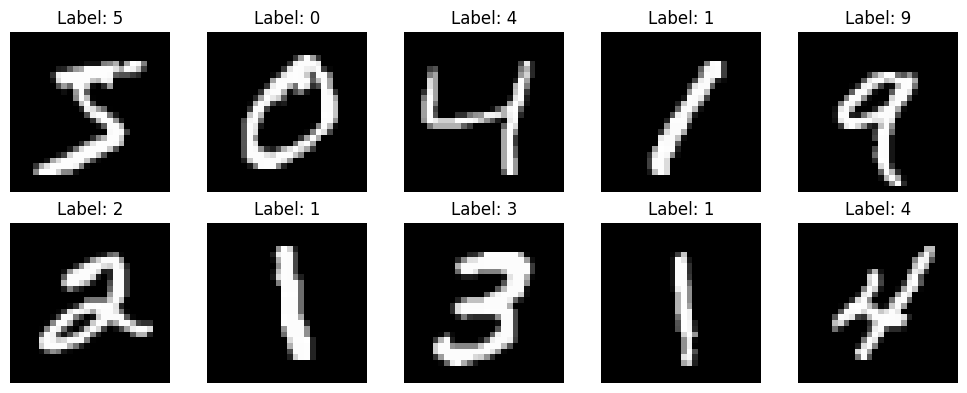

In [5]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 3: Define the CNN architecture

In [6]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Step 4: Compile the model

In [7]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## Step 5: Train the model
The practical specifies 5 epochs, batch size 64, and 10% validation data. The training history is saved for plotting.

In [8]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.9520 - loss: 0.1634 - val_accuracy: 0.9880 - val_loss: 0.0482
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9851 - loss: 0.0477 - val_accuracy: 0.9915 - val_loss: 0.0354
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 30ms/step - accuracy: 0.9901 - loss: 0.0322 - val_accuracy: 0.9890 - val_loss: 0.0417
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.9926 - loss: 0.0233 - val_accuracy: 0.9910 - val_loss: 0.0311
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9945 - loss: 0.0173 - val_accuracy: 0.9900 - val_loss: 0.0382


## Step 6: Estimate the model's performance

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9888 - loss: 0.0358
Test Loss: 0.035761527717113495
Test Accuracy: 98.87999892234802 %


## Step 7: Plot training and validation accuracy

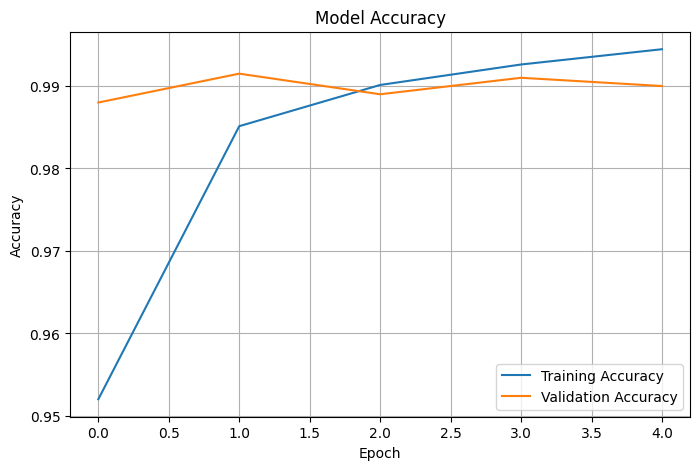

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## Step 8: Plot training and validation loss

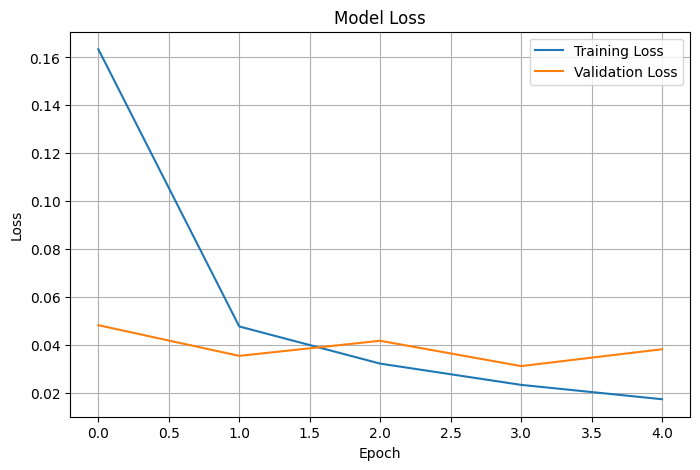

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.grid(True)
plt.show()

## Result
The CNN image-classification model was built using TensorFlow and Keras, trained on the MNIST dataset, evaluated on test data, and its training/validation accuracy and loss were plotted.

# Viva-Voce Preparation: Theory and Questions with Answers

## A. Basic concepts

**1. What is image classification?**  
Assigning an image to one class from a predefined set. Here, the classes are handwritten digits 0–9.

**2. What is a CNN?**  
A Convolutional Neural Network is a deep-learning model designed for image data. It learns visual features such as edges, curves, textures, and shapes using convolution filters.

**3. Why is CNN used for image classification?**  
CNNs learn spatial features and share filter weights across image locations. This is often more efficient than connecting every raw pixel to every neuron.

**4. What is MNIST?**  
A handwritten digit dataset containing 60,000 training images and 10,000 testing images. Each image is 28 × 28 grayscale pixels and belongs to one of 10 classes (0–9).

**5. Difference between training and testing data?**  
Training data teaches the model. Testing data is kept separate and estimates performance on unseen examples.

## B. Data preprocessing

**6. Why normalize images?**  
Dividing pixel values by 255 scales them from 0–255 to 0–1, helping make training more stable.

**7. What does `astype("float32")` do?**  
Converts the image array to 32-bit floating-point values for neural-network calculations.

**8. What does `np.expand_dims(x, axis=-1)` do?**  
Adds a final channel dimension. An image changes from (28, 28) to (28, 28, 1).

**9. Why is input shape `(28, 28, 1)`?**  
The image has 28 rows, 28 columns, and one grayscale channel. RGB images typically have three channels.

**10. What is an image channel?**  
A channel stores one component of image information. Grayscale has one channel; RGB has red, green, and blue channels.

## C. CNN architecture

**11. What is a convolution layer?**  
It applies learnable filters across an image or feature map to produce feature maps that highlight patterns.

**12. What is a filter/kernel?**  
A small matrix of learnable weights that moves across the input and computes convolution values. It can learn to detect edges and curves.

**13. What does `Conv2D(32, (3, 3))` mean?**  
A 2D convolution layer with 32 filters, each using a 3 × 3 kernel.

**14. Why use 32 and 64 filters?**  
They determine the number of feature maps produced by the two convolution layers. More filters can learn a wider variety of features.

**15. What is an activation function?**  
A function that introduces non-linearity so the network can learn complex patterns.

**16. What is ReLU?**  
Rectified Linear Unit: `f(x) = max(0, x)`. It returns zero for negative values and the input for positive values.

**17. What is max pooling?**  
A downsampling operation that selects the maximum value from each local region of a feature map.

**18. What does `MaxPooling2D((2, 2))` do?**  
Applies a 2 × 2 pooling window, normally reducing feature-map height and width by approximately half.

**19. Why use pooling?**  
It reduces feature-map dimensions and computation while retaining strong local activations.

**20. What is a feature map?**  
The output produced when a convolution filter is applied to an input.

**21. What does Flatten do?**  
Converts multi-dimensional feature maps into a one-dimensional vector for dense layers.

**22. What is a Dense layer?**  
A fully connected layer where each neuron receives input from all outputs of the previous layer.

**23. Why use `Dense(128)`?**  
It is a hidden layer with 128 neurons that learns combinations of extracted features.

**24. Why are there 10 output neurons?**  
There are ten digit classes, 0 through 9, so the model produces one output per class.

**25. What is Softmax?**  
It converts output scores into class probabilities that sum to 1. The highest probability is the predicted class.

## D. Compilation and training

**26. What does `model.compile()` do?**  
Configures the model with an optimizer, loss function, and evaluation metrics.

**27. What is an optimizer?**  
An algorithm that updates trainable model weights to reduce the loss.

**28. Which optimizer is used here?**  
Adam. It is an adaptive optimizer that uses estimates of gradients and their moments to update parameters.

**29. What is a loss function?**  
It measures the difference between model predictions and correct targets. Training attempts to minimize it.

**30. Why sparse categorical crossentropy?**  
It is suitable for multi-class classification when target labels are integer class IDs such as 0, 1, ..., 9.

**31. What is accuracy?**  
The proportion of predictions that match the correct labels, usually expressed as a percentage.

**32. What is an epoch?**  
One complete pass through the training dataset. This practical uses 5 epochs.

**33. What is batch size?**  
The number of training examples processed before an optimizer update. This practical uses 64.

**34. What is validation data?**  
Data held out from weight updates and used during training to monitor performance on unseen examples.

**35. What does `validation_split=0.1` mean?**  
It reserves 10% of the supplied training data for validation; the remaining 90% is used for training.

**36. What is backpropagation?**  
A method that computes gradients of the loss with respect to model parameters, working backward through the network using the chain rule. The optimizer uses these gradients to update weights.

## E. Evaluation and graphs

**37. What does `model.evaluate()` do?**  
Evaluates the trained model on test data and returns the loss and configured metrics, including accuracy.

**38. Difference between loss and accuracy?**  
Loss measures prediction error and is used for optimization. Accuracy measures the fraction of correctly classified examples.

**39. Why plot training and validation accuracy?**  
To see how accuracy changes across epochs and compare training performance with validation performance.

**40. Why plot training and validation loss?**  
To monitor whether prediction error decreases and whether validation performance follows training performance.

**41. What is overfitting?**  
When a model learns training examples too closely and performs worse on unseen data. A warning sign is training performance improving while validation performance worsens.

**42. What is underfitting?**  
When a model has not learned the data patterns sufficiently, resulting in poor training and validation performance.

## F. Practical-specific questions

**43. Which libraries are used?**  
TensorFlow, Keras, NumPy, and Matplotlib.

**44. What is Keras?**  
A high-level deep-learning API used to build and train neural networks. It is integrated with TensorFlow through `tf.keras`.

**45. What is TensorFlow?**  
An open-source machine-learning framework used to build and run machine-learning and deep-learning models.

**46. What is `keras.Sequential`?**  
A model in which layers are arranged in a linear sequence, with each layer feeding into the next.

**47. What does `model.summary()` display?**  
The model's layers, output shapes, and parameter counts.

**48. Difference between CNN and a fully connected neural network?**  
A CNN uses shared convolution filters to learn local spatial patterns. A fully connected network connects each neuron to all outputs of the previous layer.

**49. Can CNNs classify color images?**  
Yes. A typical RGB input shape is `(height, width, 3)`.

**50. What is the final output of this practical?**  
A trained CNN that predicts an MNIST digit class, along with test loss, test accuracy, and training/validation accuracy and loss graphs.

## Important values to remember

| Item | Value |
|---|---|
| Dataset | MNIST |
| Image size | 28 × 28 |
| Input shape | (28, 28, 1) |
| Convolution filters | 32, then 64 |
| Kernel size | 3 × 3 |
| Pool size | 2 × 2 |
| Hidden dense layer | 128 neurons |
| Output layer | 10 neurons |
| Activations | ReLU, Softmax |
| Optimizer | Adam |
| Loss | Sparse categorical crossentropy |
| Epochs | 5 |
| Batch size | 64 |
| Validation split | 0.1 (10%) |

**Source note:** The supplied practical describes training for 5 epochs with batch size 64 and validation split 0.1, but its printed code excerpt omits the `model.fit()` call. This notebook includes that required call so that `history` is created and the later plots execute.